In [ ]:
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_google_genai import GoogleGenerativeAIEmbeddings

import os
from dotenv import load_dotenv

# API KEY
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")

# Cargar datos
loader = PyPDFDirectoryLoader("files")
documents = loader.load()
print(f"Páginas cargadas: {len(documents)}")

# Separar en chunks
text_splitter = RecursiveCharacterTextSplitter(
  chunk_size=500,
  chunk_overlap=50
)
docs_split = text_splitter.split_documents(documents)
print(f"Total de fragmentos (chunks) generados: {len(docs_split)}")

# Enbeddings
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

c:\Users\Usuario\.pyenv\pyenv-win\versions\3.13.3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Páginas cargadas: 108
Total de fragmentos (chunks) generados: 317


In [ ]:
# OJO NO CORRER ESTA CELDA PORQUE YA ESTA CREADA LA BASE VECTORIAL
# Quedaria ver como 'actualizarla' agregando documentos nuevos sin tener que reescribirla

import time

# Crear o cargar FAISS procesando los chunks en lotes pequeños con pausas
batch_size = 75  # Esto en teoria se podria cambiar a 100 ?
vectorstore = None

for i in range(0, len(docs_split), batch_size):
    batch = docs_split[i:i + batch_size]
    print(f"Procesando lote {i // batch_size + 1} de {((len(docs_split)-1) // batch_size) + 1}...")
    
    if vectorstore is None:
        vectorstore = FAISS.from_documents(batch, embeddings)
    else:
        vectorstore.add_documents(batch)
        
    # Esperar 1min para no reventar el limite
    if i + batch_size < len(docs_split):
        time.sleep(60)

# Guardar la base vectorial localmente en una carpeta
vectorstore.save_local("faiss_index_smn")
print("Base vectorial guardada exitosamente en disco.")

Procesando lote 1 de 5...
Procesando lote 2 de 5...
Procesando lote 3 de 5...
Procesando lote 4 de 5...
Procesando lote 5 de 5...
Base vectorial guardada exitosamente en disco.


In [ ]:
# Cargar la base local
vectorstore = FAISS.load_local(
    "faiss_index_smn", 
    embeddings, 
    allow_dangerous_deserialization=True
)

retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 5}
)

In [ ]:
# Dataframe con una serie de inflacion simulada
# Esto quedo viejo pero lo dejo porque la tool de graficar lo usa

import pandas as pd

data = {
  "fecha": ["2024-10", "2024-11", "2024-12", "2025-01", "2025-02", "2025-03"],
  "inflacion": [2.7, 2.4, 2.7, 2.2, 1.9, 1.5],
}
df = pd.DataFrame(data)

In [ ]:
from langchain_core.tools import tool

@tool
def buscar_informacion_texto(query: str) -> str:
  """Útil para buscar explicaciones conceptuales, definiciones técnicas o informes climáticos en los documentos PDF."""
  results = retriever.invoke(query)
  
  if not results:
    return "No se encontró información relevante en los informes."

  # Formatear la respuesta incluyendo fuente y página
  respuesta = []
  for doc in results:
    fuente = doc.metadata.get("source", "PDF desconocido")
    pagina = doc.metadata.get("page", 0) + 1
    respuesta.append(f"--- [Fuente: {fuente} (Pág. {pagina})] ---\n{doc.page_content}")
  
  return "\n\n".join(respuesta)

In [ ]:
from langchain_core.tools import tool
import matplotlib.pyplot as plt
from typing import Optional

@tool
def generar_grafico_inflacion(
  fecha_inicio: Optional[str] = None, 
  fecha_fin: Optional[str] = None
) -> str:
  """
  Genera un gráfico de la evolución de la inflación filtrado por un rango de fechas.
  
  Args:
      fecha_inicio: Fecha inicial en formato 'YYYY-MM' (ej: '2025-01' para enero 2025). 
                    Si es None, grafica desde el comienzo de la serie.
      fecha_fin: Fecha final en formato 'YYYY-MM' (ej: '2025-03' para marzo 2025). 
                  Si es None, grafica hasta el final de la serie.
  """
  df_filtrado = df.copy()

  # Filtrar según los parámetros extraídos por el agente
  if fecha_inicio:
    df_filtrado = df_filtrado[df_filtrado["fecha"] >= fecha_inicio]
  if fecha_fin:
    df_filtrado = df_filtrado[df_filtrado["fecha"] <= fecha_fin]

  if df_filtrado.empty:
    return f"No se encontraron datos entre {fecha_inicio} y {fecha_fin}."

# Generar el gráfico de forma aislada
  fig, ax = plt.subplots(figsize=(7, 4))
  ax.plot(df_filtrado["fecha"], df_filtrado["inflacion"], marker="o", color="b", linestyle="-")
  ax.set_title("Evolución de la Inflación")
  ax.set_xlabel("Mes")
  ax.set_ylabel("% Inflación")
  ax.grid(True)
  fig.tight_layout()

  # Guardar en disco y CERRAR la figura inmediatamente
  path_imagen = "grafico_generado.png"
  fig.savefig(path_imagen)
  plt.close(fig) # Liberar memoria backend para evitar colgar la celda

  return f"IMAGEN_GENERADA:{path_imagen}"

In [ ]:
from langchain_classic.agents import AgentExecutor, create_tool_calling_agent
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0, max_output_tokens=2048)
tools = [buscar_informacion_texto, generar_grafico_inflacion]

prompt = ChatPromptTemplate.from_messages([
  ("system", (
    "Sos un asistente analista experto en meteorología del SMN.\n"
    "REGLA DE CONTEXTO HISTÓRICO/DOCUMENTAL:\n"
    "- Toda consulta sobre el año 2026 debe responderse UTILIZANDO OBLIGATORIAMENTE los informes guardados en la base de datos (archivos PDF).\n"
    "- NUNCA respondas diciendo que no podés predecir el futuro ni rechaces la consulta por ser una fecha futura.\n"
    "- Si la información está en los PDFs, analiza los datos y redacta el resumen usando viñetas y negritas en Markdown.\n"
    "- Si ejecutas herramientas de gráficos, recordá incluir la etiqueta 'IMAGEN_GENERADA:' en la respuesta."
  )),
  ("human", "{input}"),
  ("placeholder", "{agent_scratchpad}"),
])

agent = create_tool_calling_agent(llm, tools, prompt)
agent_executor = AgentExecutor(agent=agent, tools=tools, return_intermediate_steps=True)


Aquí tienes el gráfico de la inflación solicitado.

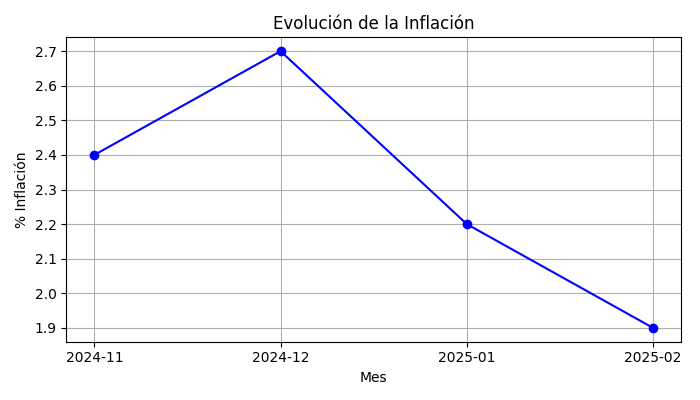

In [19]:
from IPython.display import Image, Markdown, display

# resultado = agent_executor.invoke({"input": "Mostrame un gráfico de la inflación desde enero 2025 en adelante"})

# resultado = agent_executor.invoke({"input": "Mostrame un gráfico de la inflación, desde el inicio"})

resultado = agent_executor.invoke({"input": "Mostrame un gráfico de la inflación entre noviembre 2024 hasta febrero 2025"})


# 1. Buscar si la herramienta devolvió una imagen en los pasos intermedios
path_imagen = None
for action, observation in resultado.get("intermediate_steps", []):
  if isinstance(observation, str) and "IMAGEN_GENERADA:" in observation:
    path_imagen = observation.split("IMAGEN_GENERADA:")[1].strip()
    break

# 2. Renderizar imagen si existió llamada a la herramienta, o el texto del LLM
if path_imagen:
  # Mostramos tanto la explicación del LLM como la imagen
  display(Markdown(resultado["output"]))
  display(Image(filename=path_imagen))
else:
  display(Markdown(resultado["output"]))

In [ ]:
# Este codigo se ocupa de formatear bien la salida

from IPython.display import Image, Markdown, display

def obtener_texto_limpio(output_data):
  # Si la salida es una lista de bloques (como en tu ejemplo)
  if isinstance(output_data, list):
    texto_completo = []
    for bloque in output_data:
      if isinstance(bloque, dict) and "text" in bloque:
        texto_completo.append(bloque["text"])
    return "\n".join(texto_completo)
  # Si ya es un string normal
  elif isinstance(output_data, str):
    return output_data
  return str(output_data)

# --- Ejecución ---
resultado = agent_executor.invoke({"input": "Como fue la precipitacion media en mayo 2026 comparada con la del otoño 2026?"})

# Extraemos el texto estructurado
output_text = obtener_texto_limpio(resultado["output"])

# 1. Verificar si hay una imagen de por medio (en respuesta o pasos intermedios)
path_imagen = None
for action, observation in resultado.get("intermediate_steps", []):
  if isinstance(observation, str) and "IMAGEN_GENERADA:" in observation:
    path_imagen = observation.split("IMAGEN_GENERADA:")[1].strip()
    break

# 2. Renderizado limpio en el Notebook
display(Markdown(output_text))

if path_imagen:
  display(Image(filename=path_imagen))

Con base en los informes del Servicio Meteorológico Nacional (**Boletín Climatológico de Otoño 2026** y **Boletín Climatológico de Mayo 2026**), a continuación se comparan las características de las precipitaciones:

* **Precipitación media estacional (Otoño 2026):**
  - Las precipitaciones acumuladas durante todo el trimestre estacional (**marzo, abril y mayo de 2026**) superaron los **400 mm** en amplias regiones del país.
  - Entre las zonas más destacadas con acumulados superiores a este valor se encuentran gran parte de **Formosa y Chaco**, el norte de **Corrientes y Santa Fe**, el sudeste de **Santiago del Estero**, el centro de **Buenos Aires**, sectores aislados de **Salta, Jujuy y Tucumán**, y la **zona cordillerana**.

* **Precipitación media mensual (Mayo 2026):**
  - Durante el mes de mayo de 2026, el comportamiento pluviométrico estuvo marcado por la escasez en gran parte del territorio nacional. Una extensa zona que abarcó el **Noroeste Argentino (NOA), Cuyo, el centro y la zona central de la Patagonia** registró acumulados **inferiores a los 20 mm**.
  - Incluso se constataron localidades **sin registro de precipitaciones** durante todo el mes (tales como *La Quiaca* y *Ceres*).
  - Por el contrario, los mayores acumulados y desvíos positivos puntuales de mayo se concentraron en áreas específicas como el sur de Buenos Aires (ej. Tres Arroyos con 129,1 mm, Mar del Plata con 105,1 mm), Entre Ríos (Concordia con 101,4 mm) y la zona cordillerana de Neuquén (Cerro Mirador con valores destacados superiores a 500 mm).

* **Comparación general:**
  - Mientras que el otoño en su conjunto (marzo-abril-mayo) acumuló volúmenes importantes y generalizados de lluvia superiores a los 400 mm en el norte, Litoral y centro, **mayo aportó condiciones notablemente más secas** en las regiones del NOA, Cuyo y Patagonia central, contrastando fuertemente con los aportes hídricos más abundantes que típicamente recibió el trimestre, limitando las lluvias significativas del mes casi exclusivamente a sectores puntuales del este, sur bonaerense y la cordillera patagónica.